In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pd.set_option('display.max_columns', None)
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

df.shape

(2443651, 9)

In [5]:
df.sample(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
800886,863302,B0BF4PBBKV,The Holy Quran Foldable Pouch Case (Small A5 (...,5.0,2,9.99,False,0,School & Educational Supplies
299260,317228,B0C2RKPFQ2,Buystarget 20 Pack Metal Die Cast Kids Cars Gi...,0.0,0,6.95,False,0,Kids' Play Vehicles
1589980,1790696,B08WZ5QT2V,"Ancient Greek Vase,Volute Krater 24cm,Goddess ...",0.0,0,73.00,False,0,Handmade Home Décor
683246,736254,B07HB6PZ1Z,"MisterChef® Professional Food Dehydrator, 250W...",4.1,952,49.99,False,100,Small Kitchen Appliances
1315240,1453094,B07K2FWKJ2,AquaVial Well Water Test Kit | Detect E.Coli a...,4.5,542,23.00,False,0,"Pools, Hot Tubs & Supplies"


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [23]:
# Part 1: Understanding Product Categories
frequency_table_category = df.category.value_counts().head(5).reset_index()
frequency_table_category

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


In [32]:
proportion_table_category = df.category.value_counts(normalize=True).reset_index()
proportion_table_category

,category,proportion
0,Sports & Outdoors,0.342219
1,Beauty,0.007903
2,"Handmade Clothing, Shoes & Accessories",0.007869
3,Bath & Body,0.007813
4,Birthday Gifts,0.007766
...,...,...
291,Alexa Built-In Devices,0.000044
292,Motorbike Chassis,0.000044
293,Plugs,0.000044
294,Smart Home Security & Lighting,0.000043


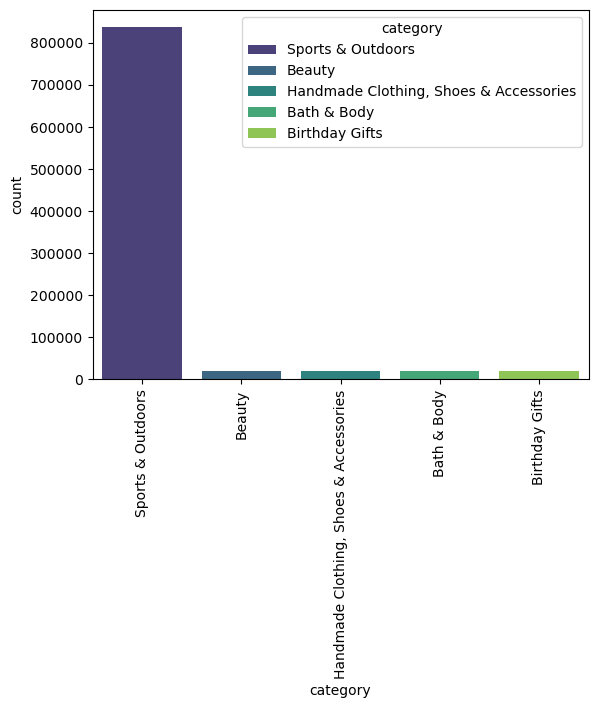

In [30]:
sns.barplot(data=frequency_table_category, x="category", y="count", hue="category", palette='viridis', legend=True) # order=order
plt.xticks(rotation=90)
plt.show()

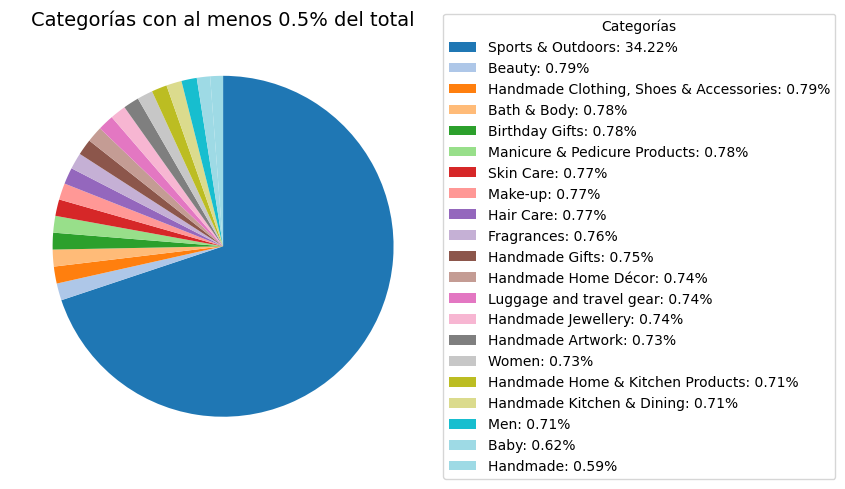

In [41]:
freq_relativas = df['category'].value_counts(normalize=True)
freq_mayores_1 = freq_relativas[freq_relativas >= 0.005]
freq_mayores_1.plot.pie(colormap='tab20',   # Paleta de colores
    startangle=90,      # Empieza desde arriba
    counterclock=False, # Orden en sentido horario
    pctdistance=0.85,
    labels=None)
plt.title("Categorías con al menos 0.5% del total", fontsize=14)
plt.ylabel('')  # Quita el label del eje Y
plt.tight_layout()
plt.legend(
    labels=[f"{idx}: {val:.2%}" for idx, val in freq_mayores_1.items()],
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    title="Categorías"
)
plt.show()

In [42]:
# Part 2: Delvng into product pricing
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [46]:
# 2.1 Measures of centrality
mean_price = df['price'].mean().round(2)

89.24

In [49]:
mode_price = df['price'].mode()
mode_price

0    9.99
Name: price, dtype: float64

In [50]:
median_price = df['price'].median()
median_price

19.09

In [60]:
# 2.2 Measures of dispersion
df["price"].describe().round(2)


count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [58]:
range = df["price"].max() - df["price"].min()
range

100000.0

<Axes: ylabel='price'>

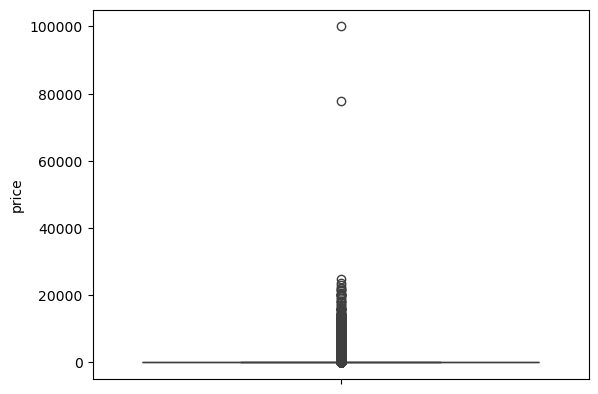

In [63]:
# 2.3 Visualization
sns.boxplot(data=df, y="price")


In [66]:
# Part 3: Unpacking product Ratings
df.sample(5)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
1037362,1146649,B0B39M3DZ3,RENZOX Slanted Tweezers Professional Eyebrow T...,4.6,192,2.99,False,0,Make-up
2196159,2542150,B07MGKYFFP,"PLA Filament 1.75mm Black, GEEETECH New 3D Pri...",4.3,23109,18.99,False,50,Arts & Crafts
1454126,1599041,B0CFKWM74S,Tropical Slogan Greetings from Paradise Men's ...,0.0,0,17.99,False,0,Sports & Outdoors
1541869,1739168,B0BFPPQGW7,LOKUO Butterfly Print Hooded Woman Oversized H...,0.0,0,19.97,False,0,Sports & Outdoors
1678068,1891052,B0BLC6NCGK,NEEWER 33inch/85cm Parabolic Softbox Quick Set...,4.7,134,133.99,False,0,Camera & Photo Accessories


In [70]:
df['stars'].describe().round(2)

count    2443651.00
mean           2.15
std            2.19
min            0.00
25%            0.00
50%            0.00
75%            4.40
max            5.00
Name: stars, dtype: float64

In [71]:
df['stars'].median()

0.0

In [72]:
df['stars'].mode()

0    0.0
Name: stars, dtype: float64

In [74]:
round(df["stars"].skew(),2)


0.08

In [76]:
round(df["stars"].kurt(), 2)

-1.93

In [77]:
print("La gráfica estará sesgada positivamente, con la cola más larga al lado derecho y de forma platicúrtica")

La gráfica estará sesgada positivamente, con la cola más larga al lado derecho y de forma platicúrtica


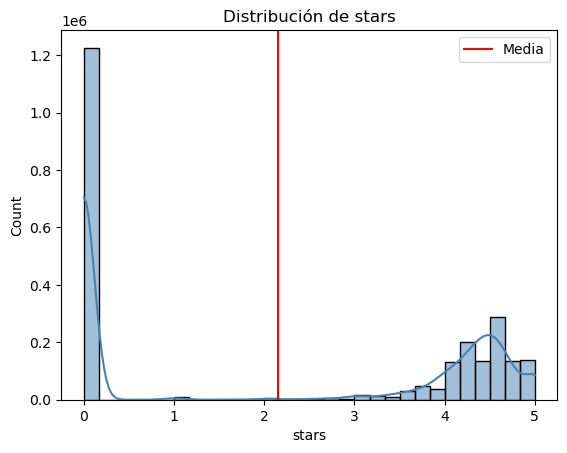

In [82]:
sns.histplot(data=df, x="stars", kde=True, bins=30, color='steelblue')

plt.axvline(df["stars"].mean(), color='red', label='Media')
plt.legend()

plt.title("Distribución de stars")
plt.show()